# Random Forest biome classification
 
 The notebook is structured the following:

 First functions are implemented that are used in the sections. The sections are structured the following:
 1. RF with original climate data
    - 1.1 Load data
    - 1.2 Optional: run grid search (takes several hours, so probably skip)
    - 1.3 Use hyperparameters from grid search to train and analyse model and evaluate on holdout area
2. RF with recalculated climate data (adjusted to local hot and cold season)
    - 2.1 preprare data
    - 2.2 prepare holdout area
    - 2.3 Optional: grid search
    - 2.4 Use hyperparameters from grid search to train and analyse model and evaluate on holdout area
3. Some additional feature importance analysis




In [1]:
from time import perf_counter

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline

# Shared geography and projection for both model variants.
SOUTH_AMERICA_CODES = frozenset(
    {"ARG", "BOL", "BRA", "CHL", "COL", "ECU", "GUY", "PRY", "PER", "SUR", "URY", "VEN"}
)
TARGET_COLUMN = "Biome_obs"
proj = ccrs.PlateCarree()

## Shared workflow helpers
 
 Reusable preparation, evaluation, and plotting functions keep both model variants consistent.

In [2]:
# Shared data-preparation and spatial-CV helpers.
# Keeping these steps in one place ensures the tuned and fixed-parameter models
# use the same geographic holdout and the same reporting conventions.

def prepare_country_holdout(climate_data, feature_columns, target_column=TARGET_COLUMN):
    """Create a clean train/validation split, holding out South America."""
    if not feature_columns:
        raise ValueError("feature_columns is empty; select model predictors first.")

    required_columns = ["Lon", "Lat", target_column, *feature_columns]
    missing_columns = sorted(set(required_columns) - set(climate_data.columns))
    if missing_columns:
        raise KeyError(f"Required model columns are missing: {missing_columns}")

    country_grid = pd.read_csv(
        "gridlist_pan_gfed_ISO3_UN_ecoregion.txt",
        sep=r"\s+",
        usecols=["Lon", "Lat", "ISO3"],
    )
    coordinates = ["Lon", "Lat"]
    if country_grid.duplicated(coordinates).any() or climate_data.duplicated(coordinates).any():
        raise ValueError("Expected unique Lon/Lat coordinates for the country-code join.")

    joined_data = climate_data.merge(
        country_grid,
        on=coordinates,
        how="left",
        validate="one_to_one",
    )
    for column in required_columns:
        joined_data[column] = pd.to_numeric(joined_data[column], errors="coerce")

    # Exclude invalid model rows before measuring how many lack a country match.
    joined_data = (
        joined_data.replace([np.inf, -np.inf], np.nan)
        .dropna(subset=required_columns)
        .copy()
    )
    unmapped_rows = int(joined_data["ISO3"].isna().sum())
    joined_data = joined_data.loc[joined_data["ISO3"].notna()].reset_index(drop=True)

    validation_mask = joined_data["ISO3"].isin(SOUTH_AMERICA_CODES)
    training_data = joined_data.loc[~validation_mask].reset_index(drop=True)
    validation_data = joined_data.loc[validation_mask].reset_index(drop=True)
    if training_data.empty or validation_data.empty:
        raise ValueError(
            "Country-code split produced an empty training or "
            "South America validation set."
        )

    if training_data[target_column].astype(int).nunique() < 2:
        raise ValueError("Training data contains fewer than two biome classes.")

    return training_data, validation_data, unmapped_rows


def make_spatial_cv_splits(training_data, X_train, y_train, n_splits=5, block_size=5):
    """Build grouped CV folds from spatial blocks to reduce geographic leakage."""
    longitude_blocks = np.floor((training_data["Lon"] + 180) / block_size).astype(int)
    latitude_blocks = np.floor((training_data["Lat"] + 90) / block_size).astype(int)
    spatial_groups = pd.factorize(
        pd.Series(list(zip(longitude_blocks, latitude_blocks)), dtype="object")
    )[0]
    if len(np.unique(spatial_groups)) < n_splits:
        raise ValueError(f"Need at least {n_splits} spatial training blocks for CV.")

    return list(
        GroupKFold(n_splits=n_splits).split(X_train, y_train, groups=spatial_groups)
    )


### Spatial grid-search utilities

In [3]:
def run_spatial_grid_search(X_train, y_train, cv_splits, parameter_grid, model_name, verbose=2):
    """Tune a median-imputed Random Forest with spatially grouped CV."""
    candidate_count = int(np.prod([len(values) for values in parameter_grid.values()]))
    fit_count = candidate_count * len(cv_splits)
    print(
        f"{model_name}: {candidate_count} candidates x {len(cv_splits)} folds "
        f"= {fit_count} fits."
    )

    # Keep the forest single-threaded; GridSearchCV parallelizes across fits.
    pipeline = make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(random_state=42, n_jobs=1, max_samples=0.5),
    )
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameter_grid,
        scoring="balanced_accuracy",
        cv=cv_splits,
        n_jobs=-1,
        pre_dispatch="n_jobs",
        refit=True,
        verbose=verbose,
        error_score="raise",
        return_train_score=True,
    )

    started = perf_counter()
    search.fit(X_train, y_train)
    elapsed_seconds = perf_counter() - started
    print(f"Grid search and final training completed in {elapsed_seconds / 60:.1f} minutes.")
    print(f"Best spatial-CV balanced accuracy: {search.best_score_:.4f}")
    print("Best parameters:", search.best_params_)
    return search, elapsed_seconds


def display_grid_search_results(search, top_n=20):
    """Show the best parameter combinations and their CV scores."""
    results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    columns = [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "mean_fit_time",
        "params",
    ]
    display(results[columns].head(top_n))
    return results

### Daily climate feature engineering

In [4]:
def add_recalculated_climate_features(climate_data, daily_sources):
    """Replace summary-file climate values with local daily-data aggregates."""
    month_lengths = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
    month_edges = np.concatenate(([0], np.cumsum(month_lengths)))
    day_columns = [f"Day{day}" for day in range(1, 366)]
    coordinates = ["Lon", "Lat"]

    def require_daily_columns(daily_table, source_name):
        missing_columns = [column for column in day_columns if column not in daily_table.columns]
        if missing_columns:
            raise ValueError(f"{source_name} is missing day columns: {missing_columns[:5]}")
        if daily_table.duplicated(coordinates).any():
            raise ValueError(f"Daily climate grid in {source_name} has duplicate coordinates.")

    def summarize_daily_values(daily_table, prefix, warmest_start=None, coldest_start=None):
        daily_values = daily_table[day_columns].to_numpy(dtype=float)
        valid_days = np.isfinite(daily_values)
        monthly_totals = []
        monthly_counts = []
        for month in range(12):
            start, end = month_edges[month:month + 2]
            month_values = daily_values[:, start:end]
            month_valid = valid_days[:, start:end]
            monthly_totals.append(np.where(month_valid, month_values, 0).sum(axis=1))
            monthly_counts.append(month_valid.sum(axis=1))

        # Ignore missing days when averaging annual and rolling-quarter values.
        annual_total = np.sum(monthly_totals, axis=0)
        annual_count = np.sum(monthly_counts, axis=0)
        quarter_totals = np.column_stack([
            sum(monthly_totals[(start + offset) % 12] for offset in range(3))
            for start in range(12)
        ])
        quarter_counts = np.column_stack([
            sum(monthly_counts[(start + offset) % 12] for offset in range(3))
            for start in range(12)
        ])
        quarter_means = np.divide(
            quarter_totals,
            quarter_counts,
            out=np.full(quarter_totals.shape, np.nan, dtype=float),
            where=quarter_counts > 0,
        )

        if warmest_start is None or coldest_start is None:
            if not np.isfinite(quarter_means).any(axis=1).all():
                raise ValueError(f"Some grid cells have no valid 3-month means in {prefix} daily data.")
            warmest_start = np.nanargmax(quarter_means, axis=1)
            coldest_start = np.nanargmin(quarter_means, axis=1)

        row_indices = np.arange(len(daily_table))
        means = daily_table[coordinates].copy()
        means[f"{prefix}_AnnualMean"] = np.divide(
            annual_total,
            annual_count,
            out=np.full(annual_total.shape, np.nan, dtype=float),
            where=annual_count > 0,
        )
        means[f"{prefix}_WarmestQuarterMean"] = quarter_means[row_indices, warmest_start]
        means[f"{prefix}_ColdestQuarterMean"] = quarter_means[row_indices, coldest_start]
        return means, warmest_start, coldest_start

    if "tmp" not in daily_sources:
        raise KeyError("Daily climate sources must include 'tmp' to select seasonal windows.")
    temperature_daily = pd.read_csv(daily_sources["tmp"])
    require_daily_columns(temperature_daily, daily_sources["tmp"])
    temperature_means, warmest_start, coldest_start = summarize_daily_values(
        temperature_daily,
        "tmp",
    )

    recalculated_data = climate_data.copy()
    quarter_selection = temperature_daily[coordinates].copy()
    quarter_selection["warmest_start"] = warmest_start
    quarter_selection["coldest_start"] = coldest_start

    for prefix, path in daily_sources.items():
        if prefix == "tmp":
            means = temperature_means
        else:
            daily_table = pd.read_csv(path)
            require_daily_columns(daily_table, path)
            daily_table = daily_table.merge(
                quarter_selection,
                on=coordinates,
                how="left",
                validate="one_to_one",
            )
            quarter_columns = ["warmest_start", "coldest_start"]
            if daily_table[quarter_columns].isna().any().any():
                raise ValueError(f"Daily climate grid in {path} does not match the temperature grid.")
            means, _, _ = summarize_daily_values(
                daily_table,
                prefix,
                daily_table["warmest_start"].to_numpy(dtype=int),
                daily_table["coldest_start"].to_numpy(dtype=int),
            )

        # Replace existing statistics instead of creating duplicate _x/_y columns.
        summary_columns = [
            f"{prefix}_{period}"
            for period in ("AnnualMean", "WarmestQuarterMean", "ColdestQuarterMean")
        ]
        recalculated_data = recalculated_data.drop(
            columns=[column for column in summary_columns if column in recalculated_data.columns]
        ).merge(
            means,
            on=coordinates,
            how="left",
            validate="one_to_one",
        )

    return recalculated_data

### Evaluation and visualization

In [12]:
def make_class_count_table(y_train, y_validation, class_labels):
    """Summarize biome sample counts and within-split class fractions."""
    counts = pd.DataFrame({
        "train_count": y_train.value_counts(),
        "validation_count": y_validation.value_counts(),
    }).reindex(class_labels, fill_value=0)
    counts.index.name = TARGET_COLUMN
    counts["biome_name"] = [class_name_by_code.get(code, str(code)) for code in counts.index]
    counts["train_fraction"] = counts["train_count"] / len(y_train)
    counts["validation_fraction"] = counts["validation_count"] / len(y_validation)
    return counts.reset_index()[
        [TARGET_COLUMN, "biome_name", "train_count", "train_fraction", "validation_count", "validation_fraction"]
    ]


def plot_confusion_matrix(y_true, y_predicted, class_labels, class_names, title):
    """Plot row-normalized confusion fractions with counts in each nonempty cell."""
    matrix = confusion_matrix(y_true, y_predicted, labels=class_labels)
    row_fractions = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1)

    fig, ax = plt.subplots(figsize=(13, 10), layout="constrained")
    image = ax.imshow(row_fractions, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(class_names)), labels=class_names, rotation=60, ha="right")
    ax.set_yticks(range(len(class_names)), labels=class_names)

    for row, column in np.ndindex(matrix.shape):
        if matrix[row, column]:
            fraction = row_fractions[row, column]
            ax.text(
                column,
                row,
                f"{matrix[row, column]}\n{fraction:.0%}",
                ha="center",
                va="center",
                fontsize=7,
                color="white" if fraction >= 0.55 else "black",
            )

    fig.colorbar(image, ax=ax, label="Fraction of actual class")
    ax.set(title=title, xlabel="Predicted biome", ylabel="Observed biome")
    ax.set_xticks(np.arange(-0.5, len(class_names), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(class_names), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.5)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_aspect("equal")
    plt.show()
    return matrix


def plot_validation_maps(validation_data, y_true, y_predicted, class_labels, title, prediction_label="Climate-only prediction", colorbar_label="Biome", figsize=(20, 7)):
    """Compare observed and predicted biome maps with a correctness panel."""
    coordinates = validation_data[["Lon", "Lat"]]
    correct = y_true.to_numpy() == y_predicted
    biome_cmap = ListedColormap(biome_rgbs)
    biome_norm = BoundaryNorm(
        np.arange(0.5, len(biome_names) + 1.5),
        biome_cmap.N,
    )
    fig, axes = plt.subplots(
        1,
        3,
        figsize=figsize,
        subplot_kw={"projection": proj},
        layout="constrained",
    )
    observed_map = axes[0].scatter(
        coordinates["Lon"], coordinates["Lat"], c=y_true,
        cmap=biome_cmap, norm=biome_norm, s=9, marker="s",
        linewidths=0, transform=proj, rasterized=True,
    )
    axes[1].scatter(
        coordinates["Lon"], coordinates["Lat"], c=y_predicted,
        cmap=biome_cmap, norm=biome_norm, s=9, marker="s",
        linewidths=0, transform=proj, rasterized=True,
    )
    axes[2].scatter(
        coordinates["Lon"], coordinates["Lat"],
        c=np.where(correct, "#238b45", "#cb181d"),
        s=9, marker="s", linewidths=0, transform=proj, rasterized=True,
    )

    axes[0].set_title("Observed biome", loc="left", fontweight="bold")
    axes[1].set_title(prediction_label, loc="left", fontweight="bold")
    axes[2].set_title(f"Correct ({correct.mean():.1%}) / incorrect", loc="left", fontweight="bold")
    for map_ax in axes:
        map_ax.set_extent([-83, -32, -57, 14], crs=proj)
        map_ax.coastlines(linewidth=0.65, color="#4b5563")
        map_ax.spines["geo"].set_edgecolor("#9ca3af")

    colorbar = fig.colorbar(
        observed_map,
        ax=axes[:2],
        orientation="horizontal",
        ticks=class_labels,
        shrink=0.9,
        pad=0.08,
        aspect=45,
        label=colorbar_label,
    )
    colorbar.ax.set_xticklabels(biome_names, rotation=45, ha="right", fontsize=8)
    axes[2].legend(
        handles=[Patch(color="#238b45", label="Correct"), Patch(color="#cb181d", label="Incorrect")],
        loc="lower left",
        frameon=True,
        framealpha=0.95,
    )
    fig.suptitle(title, fontsize=15, fontweight="bold")
    plt.show()


def plot_feature_importance(classifier, feature_columns, title, top_n=22):
    """Display impurity-based feature importance (descriptive, not causal)."""
    importance = pd.DataFrame({
        "feature": feature_columns,
        "importance": classifier.named_steps["randomforestclassifier"].feature_importances_,
    }).sort_values("importance", ascending=False, ignore_index=True)

    print("Impurity-based feature importance reflects model usage, not causal effects.")
    top_importance = importance.head(top_n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
    ax.barh(top_importance["feature"], top_importance["importance"], color="#4c78a8")
    ax.set(title=title, xlabel="Mean decrease in impurity")
    plt.show()
    display(importance)
    return importance


def evaluate_classifier(
    classifier,
    training_labels,
    validation_data,
    X_validation,
    y_validation,
    feature_columns,
    display_name,
    class_labels,
    class_names,
    prediction_label,
    importance_top_n=22,
    f1_labels=None,
):
    """Report metrics, class balance, per-class scores, and validation plots."""
    y_predicted = classifier.predict(X_validation)
    metrics = {
        "accuracy": accuracy_score(y_validation, y_predicted),
        "balanced_accuracy": balanced_accuracy_score(y_validation, y_predicted),
        "macro_f1": f1_score(
            y_validation,
            y_predicted,
            labels=f1_labels,
            average="macro",
            zero_division=0,
        ),
    }
    print(f"{display_name} validation metrics:")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f} ({value:.1%})")

    class_counts = make_class_count_table(training_labels, y_validation, class_labels)
    display(class_counts)
    report = pd.DataFrame(classification_report(
        y_validation,
        y_predicted,
        labels=class_labels,
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )).T
    display(report)

    confusion = plot_confusion_matrix(
        y_validation,
        y_predicted,
        class_labels,
        class_names,
        f"{display_name}: South America holdout confusion matrix",
    )
    plot_validation_maps(
        validation_data,
        y_validation,
        y_predicted,
        class_labels,
        f"{display_name}: South America final validation",
        prediction_label=prediction_label,
    )
    importance = plot_feature_importance(
        classifier,
        feature_columns,
        f"{display_name}: feature importance",
        top_n=importance_top_n,
    )
    return {
        "y_predicted": y_predicted,
        "metrics": metrics,
        "class_counts": class_counts,
        "report": report,
        "confusion": confusion,
        "importance": importance,
    }

### Fixed-parameter model runner

In [5]:
def train_and_plot_classifier(climate_data, feature_columns, hyperparameters):
    """Fit a fixed-parameter forest and report held-out South America results."""
    training_data, validation_data, unmapped_rows = prepare_country_holdout(
        climate_data,
        feature_columns,
    )
    X_train = training_data[feature_columns]
    y_train = training_data[TARGET_COLUMN].astype(int)
    X_validation = validation_data[feature_columns]
    y_validation = validation_data[TARGET_COLUMN].astype(int)
    class_labels = np.arange(1, len(biome_names) + 1)

    print(f"Training rows: {len(training_data):,}")
    print(f"South America validation rows: {len(validation_data):,}")
    print(f"Unmapped rows excluded: {unmapped_rows:,}")
    print(f"Number of climate features: {len(feature_columns)}")

    classifier = make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            **hyperparameters,
            random_state=42,
            n_jobs=-1,
        ),
    )
    started = perf_counter()
    classifier.fit(X_train, y_train)
    print(f"Model training completed in {(perf_counter() - started) / 60:.1f} minutes.")
    print("Hyperparameters:")
    print(hyperparameters)

    results = evaluate_classifier(
        classifier,
        y_train,
        validation_data,
        X_validation,
        y_validation,
        feature_columns,
        display_name="Climate-only classifier",
        class_labels=class_labels,
        class_names=biome_names,
        prediction_label="Climate-only prediction",
        f1_labels=class_labels,
    )
    return classifier, results

## 1. RF with original climate data

### 1.1 Load data

In [6]:
def format_rgb_string(rgb_string):
    """Convert a space-separated RGB triplet into matplotlib's float tuple."""
    return tuple(float(channel) for channel in rgb_string.split())


# The legend alternates biome labels and RGB triplets, one entry per line.
with open("legend of biomes.txt", "r", encoding="utf-8") as legend_file:
    legend_lines = [line.strip() for line in legend_file if line.strip()]

biome_names = [" ".join(line.split()[1:]) for line in legend_lines[0::2]]
biome_rgbs = [format_rgb_string(line) for line in legend_lines[1::2]]
class_name_by_code = dict(enumerate(biome_names, start=1))
biome_names

['Boreal decid forest',
 'Boreal ever forest',
 'Temp/boreal mix fo.',
 'Temp conifer forest',
 'Temp decid forest',
 'Temp broad ever fo.',
 'Temp mixed forest',
 'Trop season forest',
 'Trop rain forest',
 'Trop decid forest',
 'Moist savannas',
 'Dry savannas',
 'Tall grassland',
 'Dry grassland',
 'Xeric wood/shrub',
 'Arid shrub/steppe',
 'Desert',
 'Arctic/alpine tundra']

In [7]:
# Confirm the coordinate-to-country lookup before using it in the geographic split.
countries = pd.read_csv("gridlist_pan_gfed_ISO3_UN_ecoregion.txt", sep=r"\s+")
countries.head()

,Lon,Lat,GFED-region,Pan_2007,ISO3,UN,Ecoregion
0,-69.75,-55.25,5,Americas,CHL,152,4
1,-69.25,-55.25,5,Americas,CHL,152,4
2,-71.25,-54.75,5,Americas,CHL,152,4
3,-70.75,-54.75,5,Americas,CHL,152,4
4,-70.25,-54.75,5,Americas,CHL,152,4


In [11]:
def load_climate_data():
    """Merge model output, climate summaries, and soil predictors by grid cell."""
    climate_data = pd.read_csv("data/LPJ-GUESS_output_BERN1.csv")
    climate_sources = {
        "pre": r"data\Predaymean1961_1990_stats.csv",
        "tmax": r"data\Tmaxdaymean1961_1990_stats.csv",
        "tmin": r"data\Tmindaymean1961_1990_stats.csv",
        "tmp": r"data\Tmpdaymean1961_1990_stats.csv",
        "tswrf": r"data\Tswrfdaymean1961_1990_stats.csv",
    }

    # Prefix predictors before joining so similarly named summaries stay distinct.
    for prefix, path in climate_sources.items():
        climate_frame = pd.read_csv(path)
        climate_frame = climate_frame.rename(
            columns={
                column: f"{prefix}_{column}"
                for column in climate_frame.columns
                if column not in {"Lon", "Lat"}
            }
        )
        climate_data = climate_data.merge(
            climate_frame,
            on=["Lon", "Lat"],
            how="left",
            validate="one_to_one",
        )

    soil_data = pd.read_csv(r"data\soilmap.dat", sep=r"\s+").rename(
        columns={"lon": "Lon", "lat": "Lat"}
    )
    soil_data = soil_data.rename(
        columns={
            column: f"soil_{column}"
            for column in soil_data.columns
            if column not in {"Lon", "Lat"}
        }
    )
    return climate_data.merge(
        soil_data,
        on=["Lon", "Lat"],
        how="left",
        validate="one_to_one",
    )

In [9]:
climate_data = load_climate_data()
input_prefixes = ("pre_", "tmax_", "tmin_", "tmp_", "tswrf_", "soil_")
feature_columns = [
    column for column in climate_data.columns
    if column.startswith(input_prefixes)
]

### 1.2 Optional spatial grid search

This search evaluates 72 parameter combinations across 5 spatial folds (360 fits). Run it to retune the parameters; otherwise skip to the fixed-parameter evaluation below.

The previously selected parameters were balanced class weights, unlimited depth, sqrt feature sampling, a minimum leaf size of 5, and 300 trees.

In [ ]:
# Fit the all-summary climate/soil model using the shared spatial-CV workflow.
expanded_features = list(feature_columns)
expanded_train, expanded_validation, expanded_unmapped = prepare_country_holdout(
    climate_data,
    expanded_features,
    target_column=TARGET_COLUMN,
)
X_expanded_train = expanded_train[expanded_features]
y_expanded_train = expanded_train[TARGET_COLUMN].astype(int)
X_expanded_validation = expanded_validation[expanded_features]
y_expanded_validation = expanded_validation[TARGET_COLUMN].astype(int)
expanded_cv = make_spatial_cv_splits(
    expanded_train,
    X_expanded_train,
    y_expanded_train,
    n_splits=5,
)
expanded_class_labels = np.arange(1, len(biome_names) + 1)
expanded_class_names = [class_name_by_code.get(code, str(code)) for code in expanded_class_labels]

# Inspect class coverage in each spatial fold before launching expensive fits.
expanded_fold_counts = []
for fold_number, (fit_index, test_index) in enumerate(expanded_cv, start=1):
    fold_train_counts = y_expanded_train.iloc[fit_index].value_counts()
    fold_test_counts = y_expanded_train.iloc[test_index].value_counts()
    for code, name in zip(expanded_class_labels, expanded_class_names):
        expanded_fold_counts.append({
            "fold": fold_number,
            TARGET_COLUMN: code,
            "biome_name": name,
            "train_count": int(fold_train_counts.get(code, 0)),
            "validation_count": int(fold_test_counts.get(code, 0)),
            "validation_fraction": float(fold_test_counts.get(code, 0) / len(test_index)),
        })
display(pd.DataFrame(expanded_fold_counts))

expanded_param_grid = {
    "randomforestclassifier__n_estimators": [100, 300],
    "randomforestclassifier__max_depth": [None, 30],
    "randomforestclassifier__max_features": ["sqrt", 0.5, 0.8],
    "randomforestclassifier__min_samples_leaf": [1, 3, 5],
    "randomforestclassifier__class_weight": ["balanced", "balanced_subsample"],
}
expanded_search, expanded_search_seconds = run_spatial_grid_search(
    X_expanded_train,
    y_expanded_train,
    expanded_cv,
    expanded_param_grid,
    model_name="Expanded climate/soil spatial grid search",
)
expanded_classifier = expanded_search.best_estimator_
print(
    f"Predictors: {len(expanded_features)}; training rows: {len(expanded_train):,}; "
    f"South America validation rows: {len(expanded_validation):,}; "
    f"unmapped rows excluded: {expanded_unmapped:,}."
)
expanded_results = evaluate_classifier(
    expanded_classifier,
    y_expanded_train,
    expanded_validation,
    X_expanded_validation,
    y_expanded_validation,
    expanded_features,
    display_name="Expanded climate/soil classifier",
    class_labels=expanded_class_labels,
    class_names=expanded_class_names,
    prediction_label="Expanded-input prediction",
    importance_top_n=25,
)
y_expanded_predicted = expanded_results["y_predicted"]
expanded_metrics = expanded_results["metrics"]
expanded_class_counts = expanded_results["class_counts"]
expanded_report = expanded_results["report"]
expanded_confusion = expanded_results["confusion"]
expanded_importance = expanded_results["importance"]
expanded_cv_results = display_grid_search_results(expanded_search)

### 1.3 Evaluate the selected parameters on the South America holdout

Training rows: 44,660
South America validation rows: 6,190
Unmapped rows excluded: 8,341
Number of climate features: 67
Model training completed in 0.4 minutes.
Hyperparameters:
{'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 300}
Climate-only classifier validation metrics:
accuracy: 0.6183 (61.8%)
balanced_accuracy: 0.3511 (35.1%)
macro_f1: 0.2665 (26.6%)


,Biome_obs,biome_name,train_count,train_fraction,validation_count,validation_fraction
0,1,Boreal decid forest,1372,0.030721,NaN,NaN
1,2,Boreal ever forest,9383,0.210099,101.0,0.016317
2,3,Temp/boreal mix fo.,677,0.015159,43.0,0.006947
3,4,Temp conifer forest,0,0.000000,0.0,0.000000
4,5,Temp decid forest,3726,0.083430,74.0,0.011955
5,6,Temp broad ever fo.,1997,0.044716,629.0,0.101616
6,7,Temp mixed forest,91,0.002038,21.0,0.003393
7,8,Trop season forest,1639,0.036700,776.0,0.125363
8,9,Trop rain forest,3029,0.067824,2744.0,0.443296
9,10,Trop decid forest,1242,0.027810,276.0,0.044588


,precision,recall,f1-score,support
Boreal decid forest,0.000000,0.000000,0.000000,0.000000
Boreal ever forest,0.285714,0.019802,0.037037,101.000000
Temp/boreal mix fo.,0.058015,0.883721,0.108883,43.000000
Temp conifer forest,0.000000,0.000000,0.000000,0.000000
Temp decid forest,0.000000,0.000000,0.000000,74.000000
Temp broad ever fo.,0.848425,0.685215,0.758135,629.000000
Temp mixed forest,0.000000,0.000000,0.000000,21.000000
Trop season forest,0.428470,0.775773,0.552040,776.000000
Trop rain forest,0.891881,0.820700,0.854811,2744.000000
Trop decid forest,0.541063,0.405797,0.463768,276.000000


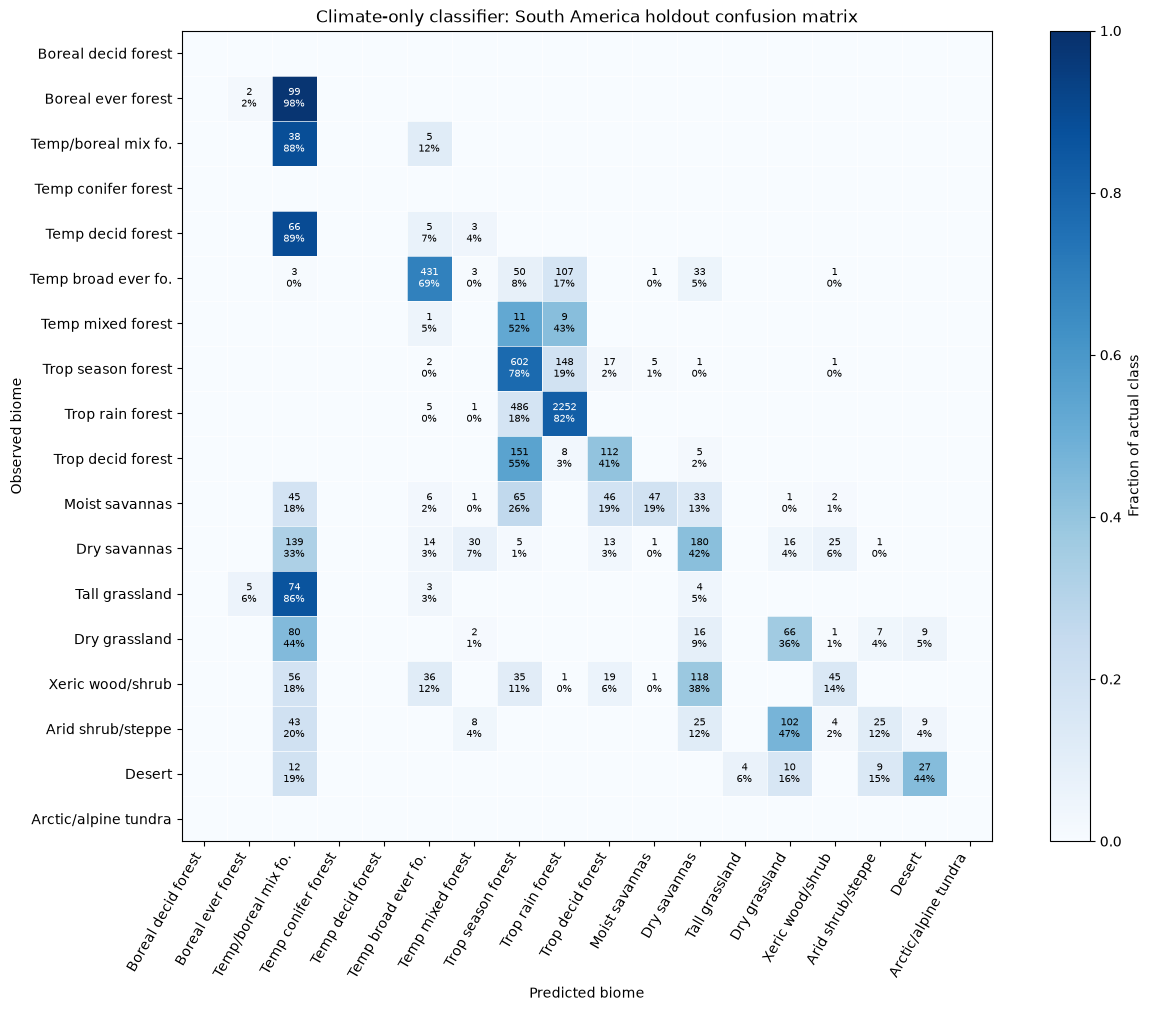

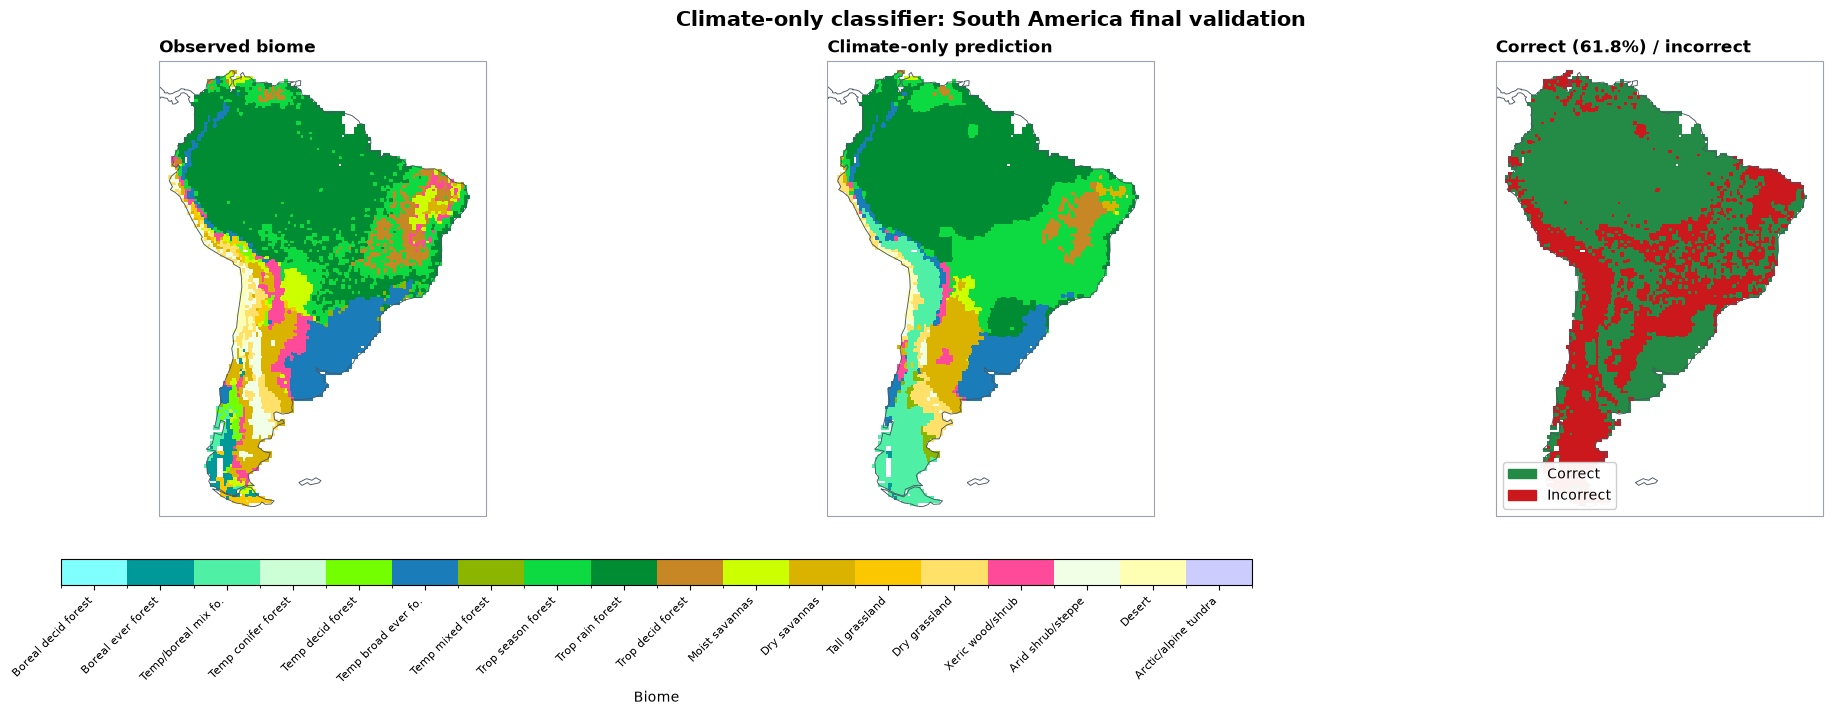

Impurity-based feature importance reflects model usage, not causal effects.


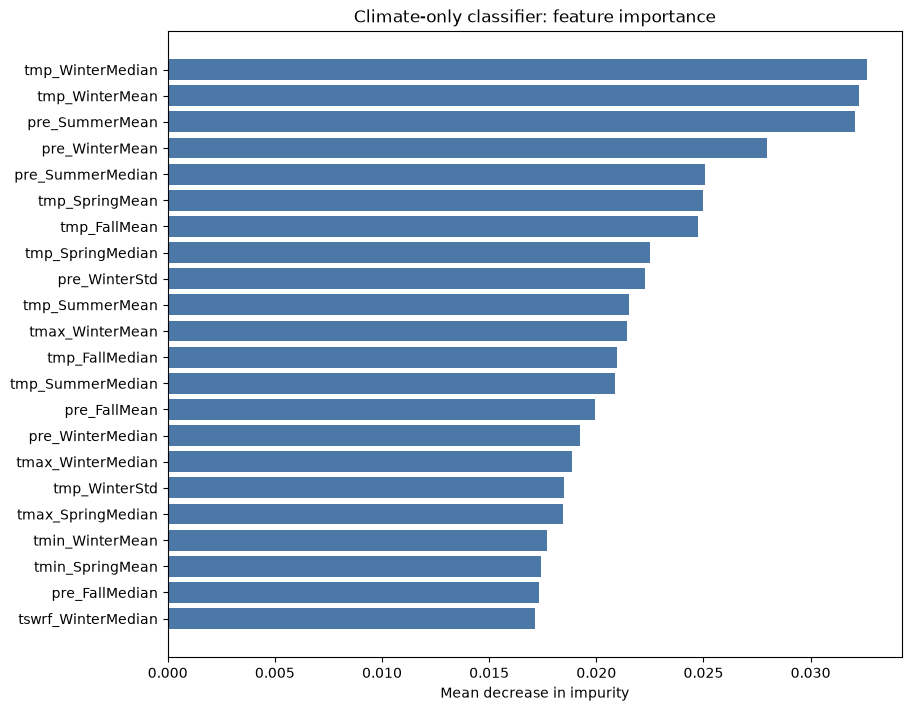

,feature,importance
0,tmp_WinterMedian,0.032617
1,tmp_WinterMean,0.032262
2,pre_SummerMean,0.032083
3,pre_WinterMean,0.027945
4,pre_SummerMedian,0.025081
...,...,...
62,soil_silt,0.004338
63,soil_clay,0.004085
64,soil_orgC,0.003782
65,soil_cellfraction,0.003208


In [13]:
# Previously selected parameters from the original climate-summary grid search.
hyperparameters_tuning = {
    "class_weight": "balanced",
    "max_depth": None,
    "max_features": "sqrt",
    "min_samples_leaf": 5,
    "n_estimators": 300,
}
climate_only_classifier, climate_only_results = train_and_plot_classifier(
    climate_data,
    feature_columns,
    hyperparameters_tuning,
)

## 2. Random Forest with locally recalculated climate features

### 2.1 Recalculate climate data 
Calculate mean temperatures for Warmest/Coldest Quarter locally

In [14]:
daily_climate_sources = {
    "pre": r"data\Predaymean1961_1990.csv",
    "tmax": r"data\Tmaxdaymean1961_1990.csv",
    "tmin": r"data\Tmindaymean1961_1990.csv",
    "tmp": r"data\Tmpdaymean1961_1990.csv",
    "tswrf": r"data\Tswrfdaymean1961_1990.csv",
}
climate_data = add_recalculated_climate_features(climate_data, daily_climate_sources)
print("Replaced summary statistics with annual and local warmest/coldest-quarter daily means.")

Replaced summary statistics with annual and local warmest/coldest-quarter daily means.


### 2.2 Prepare shared predictors and holdout

In [15]:
# Climate and soil predictors used by both recalculated-data model paths.
CLIMATE_FEATURE_COLUMNS = [
    "soil_clay", "soil_silt", "soil_sand", "soil_orgC", "soil_CN", "soil_pH", "soil_cellfraction",
    *[
        f"{prefix}_{period}"
        for prefix in ("tmp", "pre", "tmax", "tmin", "tswrf")
        for period in ("AnnualMean", "WarmestQuarterMean", "ColdestQuarterMean")
    ],
]
climate_only_train, climate_only_validation, climate_only_unmapped = prepare_country_holdout(
    climate_data,
    CLIMATE_FEATURE_COLUMNS,
)
X_climate_train = climate_only_train[CLIMATE_FEATURE_COLUMNS]
y_climate_train = climate_only_train[TARGET_COLUMN].astype(int)
X_climate_validation = climate_only_validation[CLIMATE_FEATURE_COLUMNS]
y_climate_validation = climate_only_validation[TARGET_COLUMN].astype(int)
climate_only_cv = make_spatial_cv_splits(
    climate_only_train,
    X_climate_train,
    y_climate_train,
    n_splits=5,
)
climate_only_class_labels = np.arange(1, len(biome_names) + 1)

### 2.3 Optional spatial grid search

This mirrors the original-summary search (360 fits). Run it to retune the recalculated predictors; otherwise skip to the fixed-parameter evaluation.

In [ ]:
# Tune the climate/soil Random Forest with the shared spatial folds.
climate_only_param_grid = {
    "randomforestclassifier__n_estimators": [100, 300],
    "randomforestclassifier__max_depth": [None, 30],
    "randomforestclassifier__max_features": ["sqrt", 0.5, 0.8],
    "randomforestclassifier__min_samples_leaf": [1, 3, 5],
    "randomforestclassifier__class_weight": ["balanced", "balanced_subsample"],
}
climate_only_search, climate_only_search_seconds = run_spatial_grid_search(
    X_climate_train,
    y_climate_train,
    climate_only_cv,
    climate_only_param_grid,
    model_name="Climate-only spatial grid search",
)
climate_only_classifier = climate_only_search.best_estimator_
print(
    f"Training rows: {len(climate_only_train):,}; "
    f"South America validation rows: {len(climate_only_validation):,}; "
    f"unmapped rows excluded: {climate_only_unmapped:,}."
)
climate_only_results = evaluate_classifier(
    climate_only_classifier,
    y_climate_train,
    climate_only_validation,
    X_climate_validation,
    y_climate_validation,
    CLIMATE_FEATURE_COLUMNS,
    display_name="Climate-only classifier",
    class_labels=climate_only_class_labels,
    class_names=biome_names,
    prediction_label="Climate-only prediction",
)
y_climate_validation_predicted = climate_only_results["y_predicted"]
climate_only_validation_metrics = climate_only_results["metrics"]
climate_only_class_counts = climate_only_results["class_counts"]
climate_only_report = climate_only_results["report"]
climate_only_confusion = climate_only_results["confusion"]
climate_only_importance = climate_only_results["importance"]
climate_only_cv_results = display_grid_search_results(climate_only_search)

### 2.4 Fixed-parameter evaluation and model comparison

The cell below applies the selected parameter set to the locally recalculated climate features.

Training rows: 44,660
South America validation rows: 6,190
Unmapped rows excluded: 8,341
Number of climate features: 22
Model training completed in 0.3 minutes.
Hyperparameters:
{'n_estimators': 300, 'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5, 'class_weight': 'balanced', 'max_samples': 0.5}
Climate-only classifier validation metrics:
accuracy: 0.7057 (70.6%)
balanced_accuracy: 0.4663 (46.6%)
macro_f1: 0.3696 (37.0%)


,Biome_obs,biome_name,train_count,train_fraction,validation_count,validation_fraction
0,1,Boreal decid forest,1372,0.030721,NaN,NaN
1,2,Boreal ever forest,9383,0.210099,101.0,0.016317
2,3,Temp/boreal mix fo.,677,0.015159,43.0,0.006947
3,4,Temp conifer forest,0,0.000000,0.0,0.000000
4,5,Temp decid forest,3726,0.083430,74.0,0.011955
5,6,Temp broad ever fo.,1997,0.044716,629.0,0.101616
6,7,Temp mixed forest,91,0.002038,21.0,0.003393
7,8,Trop season forest,1639,0.036700,776.0,0.125363
8,9,Trop rain forest,3029,0.067824,2744.0,0.443296
9,10,Trop decid forest,1242,0.027810,276.0,0.044588


,precision,recall,f1-score,support
Boreal decid forest,0.000000,0.000000,0.000000,0.000000
Boreal ever forest,0.526316,0.594059,0.558140,101.000000
Temp/boreal mix fo.,0.165049,0.790698,0.273092,43.000000
Temp conifer forest,0.000000,0.000000,0.000000,0.000000
Temp decid forest,0.500000,0.081081,0.139535,74.000000
Temp broad ever fo.,0.927305,0.831479,0.876781,629.000000
Temp mixed forest,0.187500,0.142857,0.162162,21.000000
Trop season forest,0.515607,0.574742,0.543571,776.000000
Trop rain forest,0.878227,0.917274,0.897326,2744.000000
Trop decid forest,0.563910,0.271739,0.366748,276.000000


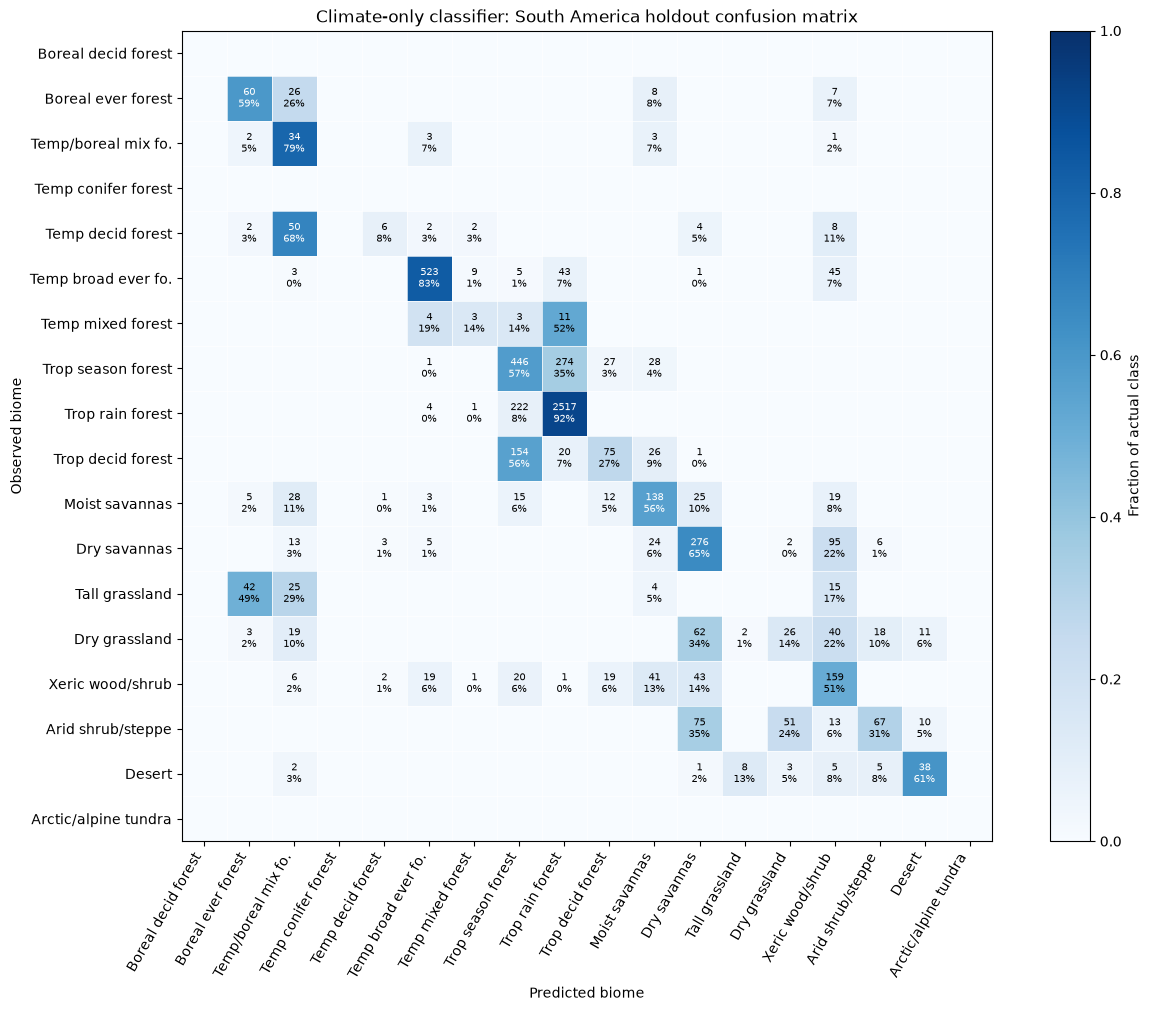

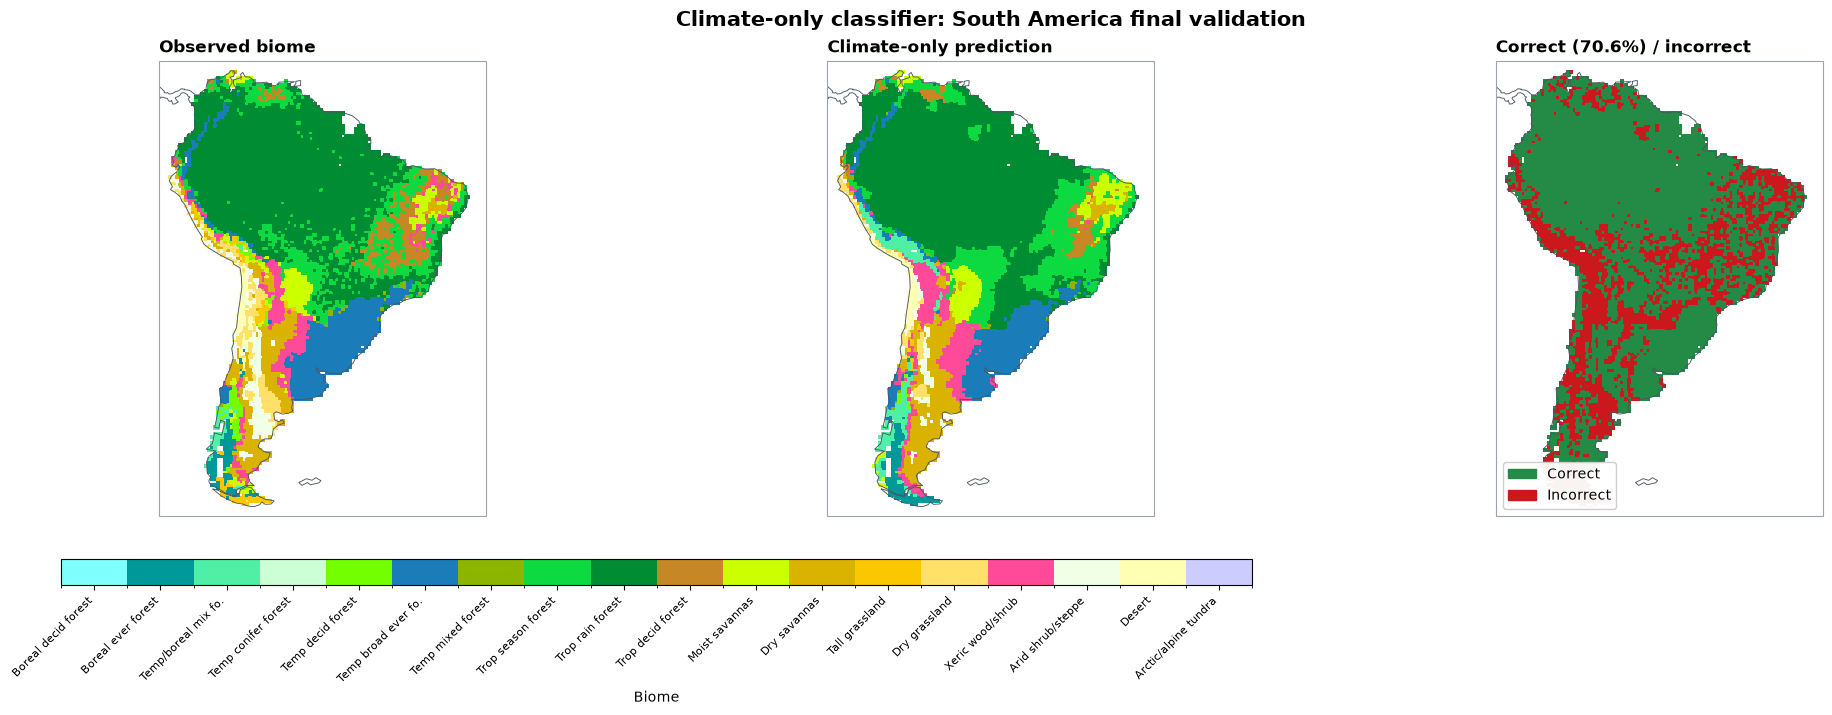

Impurity-based feature importance reflects model usage, not causal effects.


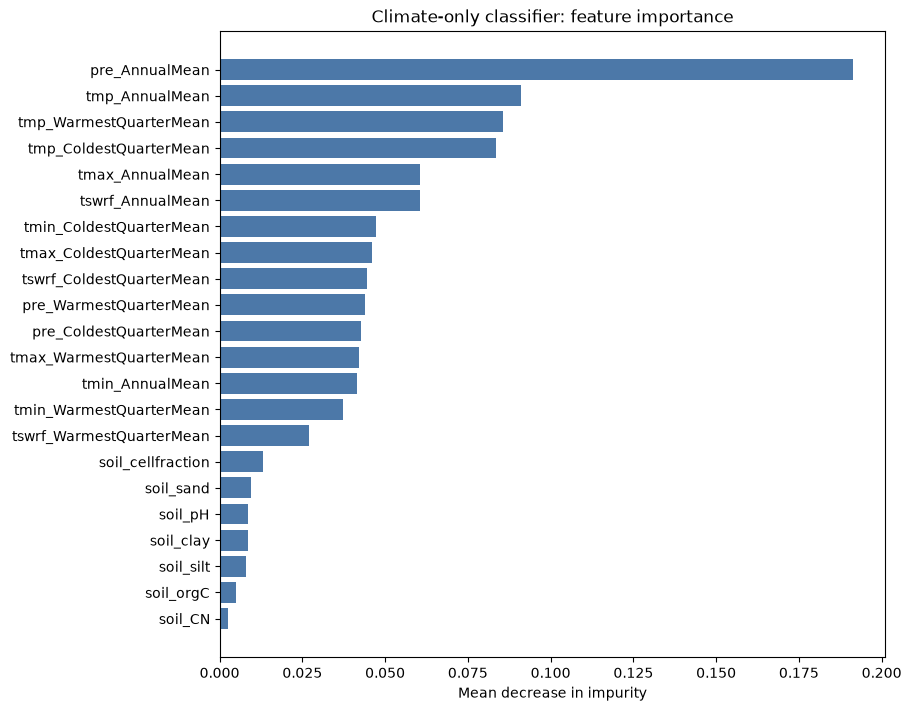

,feature,importance
0,pre_AnnualMean,0.191491
1,tmp_AnnualMean,0.091097
2,tmp_WarmestQuarterMean,0.085761
3,tmp_ColdestQuarterMean,0.083533
4,tmax_AnnualMean,0.060537
5,tswrf_AnnualMean,0.060392
6,tmin_ColdestQuarterMean,0.047277
7,tmax_ColdestQuarterMean,0.045931
8,tswrf_ColdestQuarterMean,0.044578
9,pre_WarmestQuarterMean,0.043968


In [16]:
hyperparameters_tuning = {
    "n_estimators": 300,
    "max_depth": None,
    "max_features": 0.5,
    "min_samples_leaf": 5,
    "class_weight": "balanced",
    "max_samples": 0.5,
}

climate_only_classifier, climate_only_results = train_and_plot_classifier(
    climate_data,
    CLIMATE_FEATURE_COLUMNS,
    hyperparameters_tuning,
)

## 3. Feature relationships and model interpretation

### Predictor correlation

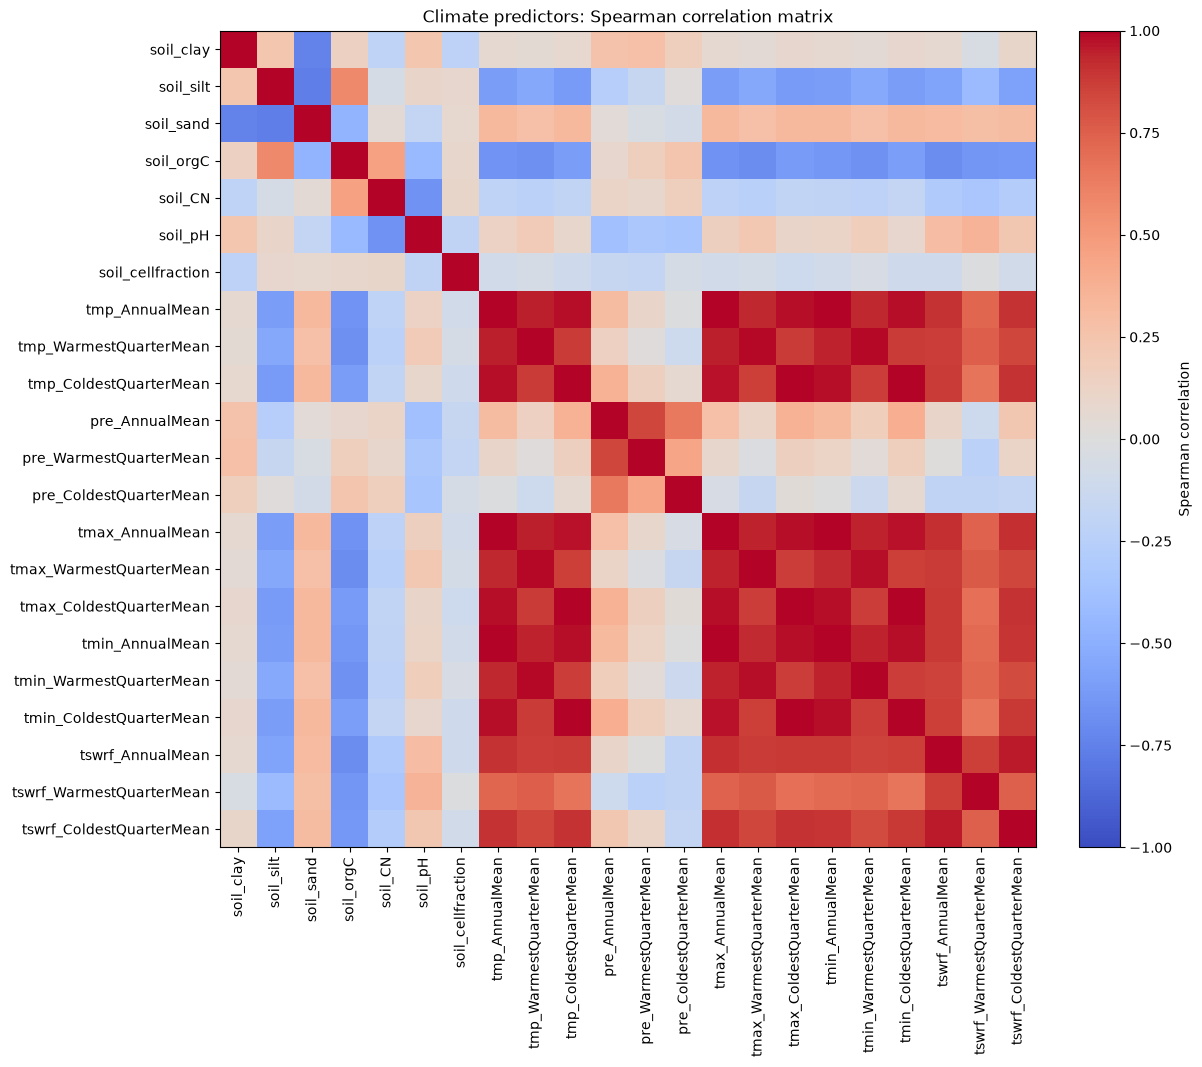

Feature pairs with |Spearman correlation| >= 0.8: 57


,feature_1,feature_2,spearman_correlation,absolute_correlation
0,tmp_ColdestQuarterMean,tmin_ColdestQuarterMean,0.997638,0.997638
1,tmp_AnnualMean,tmin_AnnualMean,0.996598,0.996598
2,tmp_ColdestQuarterMean,tmax_ColdestQuarterMean,0.995693,0.995693
3,tmp_AnnualMean,tmax_AnnualMean,0.995448,0.995448
4,tmax_ColdestQuarterMean,tmin_ColdestQuarterMean,0.994271,0.994271
5,tmax_AnnualMean,tmin_AnnualMean,0.992845,0.992845
6,tmp_WarmestQuarterMean,tmax_WarmestQuarterMean,0.990520,0.990520
7,tmp_WarmestQuarterMean,tmin_WarmestQuarterMean,0.990305,0.990305
8,tmax_WarmestQuarterMean,tmin_WarmestQuarterMean,0.984361,0.984361
9,tmin_AnnualMean,tmin_ColdestQuarterMean,0.982880,0.982880


In [17]:
# ------------------------------------------------------------
# 1. Spearman correlation matrix
#    Use training predictors, not the South America holdout.
# ------------------------------------------------------------

climate_only_correlation = (
    X_climate_train[CLIMATE_FEATURE_COLUMNS]
    .corr(method="spearman")
)

fig, ax = plt.subplots(
    figsize=(max(10, len(CLIMATE_FEATURE_COLUMNS) * 0.55),
             max(8, len(CLIMATE_FEATURE_COLUMNS) * 0.48)),
    layout="constrained"
)

im = ax.imshow(
    climate_only_correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(
    range(len(CLIMATE_FEATURE_COLUMNS)),
    labels=CLIMATE_FEATURE_COLUMNS,
    rotation=90
)

ax.set_yticks(
    range(len(CLIMATE_FEATURE_COLUMNS)),
    labels=CLIMATE_FEATURE_COLUMNS
)

fig.colorbar(im, ax=ax, label="Spearman correlation")

ax.set_title("Climate predictors: Spearman correlation matrix")

plt.show()

# ------------------------------------------------------------
# 2. List strongly correlated feature pairs
# ------------------------------------------------------------

correlation_threshold = 0.8

upper_triangle = np.triu(
    np.ones(climate_only_correlation.shape, dtype=bool),
    k=1
)

correlation_pairs = (
    climate_only_correlation
    .where(upper_triangle)
    .stack()
    .rename("spearman_correlation")
    .reset_index()
)

correlation_pairs.columns = [
    "feature_1",
    "feature_2",
    "spearman_correlation"
]

correlation_pairs["absolute_correlation"] = (
    correlation_pairs["spearman_correlation"].abs()
)

strong_correlation_pairs = (
    correlation_pairs.loc[
        correlation_pairs["absolute_correlation"]
        >= correlation_threshold
    ]
    .sort_values("absolute_correlation", ascending=False)
    .reset_index(drop=True)
)

print(
    f"Feature pairs with |Spearman correlation| >= "
    f"{correlation_threshold}: "
    f"{len(strong_correlation_pairs)}"
)

display(strong_correlation_pairs)


### Impurity and permutation importance

,feature,impurity_importance,permutation_mean,permutation_std
0,pre_AnnualMean,0.191491,0.243312,0.004454
1,tmp_ColdestQuarterMean,0.083533,0.125943,0.006278
2,tmp_AnnualMean,0.091097,0.084474,0.004175
3,tmp_WarmestQuarterMean,0.085761,0.047341,0.003428
4,tmax_WarmestQuarterMean,0.042066,0.031004,0.002542
5,pre_ColdestQuarterMean,0.042797,0.027341,0.003064
6,pre_WarmestQuarterMean,0.043968,0.026791,0.002744
7,tswrf_AnnualMean,0.060392,0.011356,0.003013
8,tmin_AnnualMean,0.041408,0.005268,0.001145
9,tswrf_WarmestQuarterMean,0.026866,0.004993,0.001875


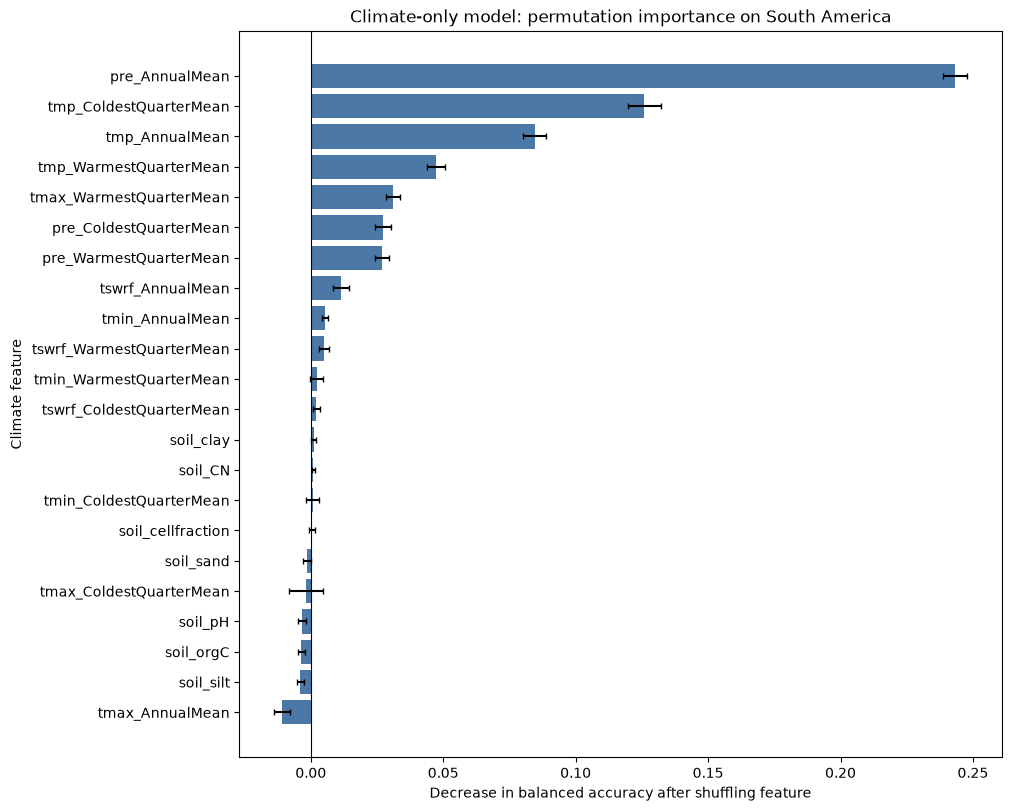

In [18]:


# ------------------------------------------------------------
# 1. Impurity-based importance
# ------------------------------------------------------------

climate_only_rf = (
    climate_only_classifier
    .named_steps["randomforestclassifier"]
)

climate_only_feature_importance = pd.DataFrame({
    "feature": CLIMATE_FEATURE_COLUMNS,
    "impurity_importance": climate_only_rf.feature_importances_
})

# ------------------------------------------------------------
# 2. Permutation importance on South America validation data
# ------------------------------------------------------------

climate_only_permutation = permutation_importance(
    climate_only_classifier,
    X_climate_validation,
    y_climate_validation,
    scoring="balanced_accuracy",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

climate_only_permutation_importance = pd.DataFrame({
    "feature": CLIMATE_FEATURE_COLUMNS,
    "permutation_mean": climate_only_permutation.importances_mean,
    "permutation_std": climate_only_permutation.importances_std
})

climate_only_importance_comparison = (
    climate_only_feature_importance
    .merge(climate_only_permutation_importance, on="feature")
    .sort_values("permutation_mean", ascending=False)
    .reset_index(drop=True)
)

display(climate_only_importance_comparison)

# ------------------------------------------------------------
# 3. Plot the top 25 features by permutation importance
# ------------------------------------------------------------

top_features = (
    climate_only_importance_comparison
    .head(25)
    .sort_values("permutation_mean")
)

fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")

ax.barh(
    top_features["feature"],
    top_features["permutation_mean"],
    xerr=top_features["permutation_std"],
    color="#4c78a8",
    capsize=2
)

ax.axvline(0, color="black", linewidth=0.8)
ax.set(
    title="Climate-only model: permutation importance on South America",
    xlabel="Decrease in balanced accuracy after shuffling feature",
    ylabel="Climate feature"
)

plt.show()

